# Week 7: Regression

# First time here?



1.   Copy this file to your Google Drive so you can edit it: **File->Save a copy in Drive** (requires a personal Google account)
2.   Done? Consider giving your copy a better name (e.g., including your name and/or student ID) - just click on the filename in the top left and edit it.
3.   (Want to re-open your copy in future? Go: **File->Open notebook** and select the Google Drive tab)
4.   (Want to find your file on your Google Drive? Google puts Colab files in a folder called "Colab Notebooks")

# Scikit-learn implementations (regressors)

In this notebook we're going to focus on using existing regression model implementations: the ones provided by the [Scikit-learn](https://scikit-learn.org/stable/) package.

As well as learning how to use them, we'll also introduce some methods for evaluating and interpreting the resulting models.

In the extension exercises, there are chances to work on re-implementing the models for yourself.

## The diabetes_progression.csv data

Let's try working with some *regression data* where we need to predict a numerical target value, rather than a categorical one.

The diabetes_progression.csv file contains information for a group of patients with a known pre-existing condition (diabetes) and the interesting challenge is whether we can predict a numeric measure of disease progression 1 year from now.

We keep a copy of the diabetes_progression data on an MMU web server for easy access and use in these labs: [diabetes_progression.csv](https://helward.mmu.ac.uk/STAFF/J.Darby/ML/diabetes_progression.csv)

Click the link to download the .csv file to your local machine, and open it up in Excel to have a look. Complete the questions below:

1.   How many observations are there? ** 11**
2.   What is the name of the target feature? ** Progress**
3.   Which one of the predictive features has been converted from categorical to numerical values? ** Sex **
4.   Do the predictive feature values vary over different ranges? ** Yes, there are some smaller values with decimals e.g. 3,4,5,6 etc and theres also  higher values 90-170 etc**
5.   Has the data been sorted in any way? ** Yes the data was sorted in age from yougest to oldest**

**You can assume that this data is clean (meaning that there are no missing/incorrect/irrelevant feature values, etc).**


## Check the docs

Here is a list of possible regression models we could use based on what we've learned so far. They are simple conversions of classification models we already know well - the only one that can't be converted being Naive Bayes - plus linear regression:
1. k-Nearest neighbours regressor: [`KNeighborsRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html)
2. Decision tree regressor: [`DecisionTreeRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html)
3. Voting regressor ensemble [`VotingRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingRegressor.html)
4. Bagging regressor ensemble [`BaggingRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingRegressor.html)
5. Random forest regressor: [`RandomForestRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor)
6. Linear regressor: [`LinearRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html) (works by solving the Normal equation) or [`SGDRegressor`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.SGDRegressor.html) (works by using gradient descent)

**Tip**: As always, if you know the name of the model you want to use, but not the name of the specific class... A quick Google for "sklearn" (a common abbreviation of Scikit-learn), plus the name of the model, plus the kind of problem you're working on will typically do the trick. E.g., "sklearn decision tree regression". (Or of course you can ask YFLLM.)

*    **Click through to one of the documentation pages and have a quick look - it should be familiar.**

**Note**: the classes look just the same as the ones for the classification models we're used to, except they accept/return continuous numerical values instead of labels, and they don't have `predict_proba()` methods.

## Basic supervised learning recipe

The code below shows our basic supervised learning recipe again. We're using it to train and evaluate on the diabetes_regression.csv data again, but this time we're using [Scikit-learn](https://scikit-learn.org/stable/)'s k-NN regressor implementation.

**Note: you may now know some possible improvements to the basic recipe, and there are chances to try making them later in the lab.**

For now, just note the following changes to the basic recipe when performing regression (versus classification):
1. we use a regression model and not a classification model (because we're predicting numerical values, not categorical ones);
2. we update our variable names to `values`, `train_values` and `test_values` to reflect this (rather than `labels`, `train_labels` and `test_labels`)
3. we calculate the mean square error (MSE) as our evaluation metric (because we're comparing two numerical values, not two categorical values).

**Tip**: the regression models are sensitive to predictive feature value ranges in the same way as their corresponding classification models, and so here, with k-NN, we are using z-score standardisation via the `StandardScaler` class.

In [1]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.neighbors import KNeighborsRegressor
from sklearn.preprocessing import StandardScaler

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/diabetes_progression.csv')

# Set the name of the target feature
target_feature = 'Progress'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing values ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_values = observations_test[target_feature].to_numpy()

# Split into training examples and training values ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_values = observations_train[target_feature].to_numpy()

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Create a k-NN regression model object:
model = KNeighborsRegressor()

# Fit the model to our training data
model.fit(train_examples, train_values)

# Use the model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Calculate the model's mean square error (MSE) - the average square of the error between its predictions and the testing values
mse = np.sum( (predictions - test_values)**2 ) / len(test_values)
print(f"MSE: {mse:.3f}")
print(f"Root MSE: {np.sqrt(mse):.3f}")

MSE: 3464.506
Root MSE: 58.860


Remember: **lower is better** when it comes to MSE. It can also help to take the square root of your MSE score because the result has the same units as your original target feature and is easier to compare. Here we're about 59 points off the patient progression score, on average.

The regression model objects are broadly the same as the classification objects we're used to, with one exception: they don't have a `predict_proba()` method. We're no longer predicting categorical values that we can assign different probabilities to; we're predicting continuous numerical values instead.

Add a line of code below to predict the disease progression score for the first testing example using the trained model. Print out the true value as well, for comparison:

In [2]:
# Add your code on the lines below:

# Predict the progression score for the first testing example
first_prediction = model.predict(test_examples[0].reshape(1, -1))[0]

# Get the true value
true_value = test_values[0]

# Print both
print("Predicted value:", round(first_prediction, 3))
print("True value:", true_value)



Predicted value: 267.8
True value: 274


# Hyperparameter investigation

The same hyperparameters are relevant in the same ways as they were in classification problems. E.g., for a k-NN regressor, lower k describes the training data more precisely but puts us at greater risk of overfitting.

Below, we've used our standard for loop approach to investigate the impact of varying k on MSE for the diabetes_progression.csv data.

*    Based on the resulting graph, approximately what value of k would you choose for this data? ** 8**

**Tip:** Remember, lower MSE is better.

Mean square error (MSE): 6142.364
Mean square error (MSE): 3334.362
Mean square error (MSE): 3012.352
Mean square error (MSE): 2807.024
Mean square error (MSE): 2834.314
Mean square error (MSE): 2810.352
Mean square error (MSE): 2806.525
Mean square error (MSE): 2740.037
Mean square error (MSE): 2741.697
Mean square error (MSE): 2772.856
Mean square error (MSE): 2782.428
Mean square error (MSE): 2821.358
Mean square error (MSE): 2842.268
Mean square error (MSE): 2854.255
Mean square error (MSE): 2884.819
Mean square error (MSE): 2910.469
Mean square error (MSE): 2944.669
Mean square error (MSE): 2989.171
Mean square error (MSE): 3007.515
Mean square error (MSE): 3053.488
Mean square error (MSE): 3058.936
Mean square error (MSE): 3096.581
Mean square error (MSE): 3119.769
Mean square error (MSE): 3158.275
Mean square error (MSE): 3209.017
Mean square error (MSE): 3248.172


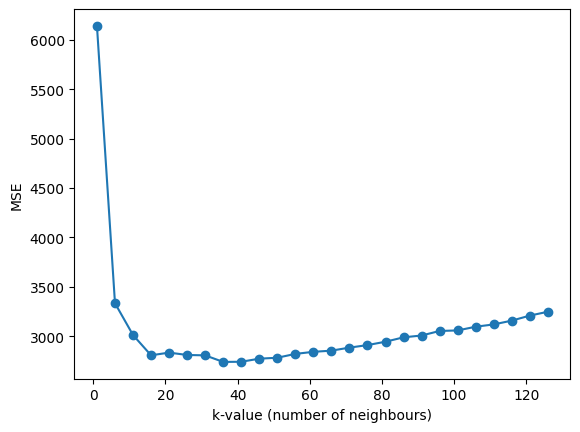

In [3]:
# Import the packages we use
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsRegressor
import matplotlib.pyplot as plt

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/diabetes_progression.csv')

# Set the name of the target feature
target_feature = 'Progress'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing values ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_values = observations_test[target_feature].to_numpy()

# Split into training examples and training values ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_values = observations_train[target_feature].to_numpy()

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Define the range of hyperparameter values we're interested in
k_vals = list(range(1, 131, 5))
# And a list to hold the resulting MSEs
mses = []

# Create a k-NN regression model object
model = KNeighborsRegressor()

for k in k_vals:

  # Update the number of nearest neighbours our model is using
  model.set_params(n_neighbors=k)

  # Call the model's fitting/training algorithm, passing in our training examples and training values
  model.fit(train_examples, train_values)

  # Use the trained model to generate predictions based on our testing examples
  predictions = model.predict(test_examples)

  # Find the mean squared error (MSE) between the model's predictions and the testing values
  mse = np.sum( (predictions - test_values)**2 ) / len(test_values)
  # Display the MSE as a single quantitative measure of overall performance
  print(f"Mean square error (MSE): {mse:.3f}")

  # Store this latest MSE result
  mses.append(mse)

# Show evaluation results graphically
plt.figure()
plt.plot(k_vals, mses, marker='o', linestyle='-')
plt.xlabel('k-value (number of neighbours)')
plt.ylabel('MSE')
plt.show()

# Parity plots

We can't generate a confusion matrix for a regression problem because we're no longer predicting discrete categorical values. But the closest thing to a confusion matrix for a regression problem is a _parity plot_. This is a scatter plot of every testing value against its corresponding predicted value. If the model is working perfectly then we would get a straight 45 degree diagonal distribution of points. In practice we can plot that perfect diagonal line to get a quick visual sense of how well our model is performing from how far the scattered points lie from the diagonal. See the example below:

*    **The first time you run it, the plot will show the result for the last k value tested by the for loop above - add some code to see the result for a better k-value based on the graph above**

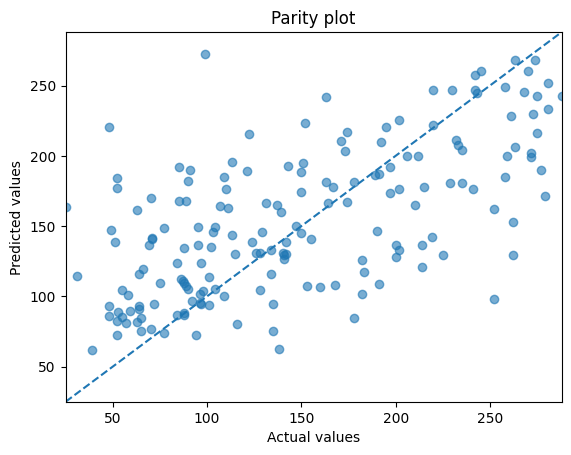

In [6]:
import numpy as np
import matplotlib.pyplot as plt

# Create a better model using k ≈ 8
better_model = KNeighborsRegressor(n_neighbors=8)

# Train it
better_model.fit(train_examples, train_values)

# Generate new predictions
predictions = better_model.predict(test_examples)


# Visualise regressor performance with a parity plot
plt.figure()

# scatter plot
plt.scatter(test_values, predictions, alpha=0.6)

# 45-degree reference line
min_val = min(np.min(test_values), np.min(predictions))
max_val = max(np.max(test_values), np.max(predictions))

plt.plot([min_val, max_val], [min_val, max_val], linestyle="--")

# labels
plt.xlabel("Actual values")
plt.ylabel("Predicted values")
plt.title("Parity plot")

# set square axes to help us interpret
plt.xlim(min_val, max_val)
plt.ylim(min_val, max_val)

plt.show()

# Linear regression (normal equation)

Let's have a closer look at the new regression model we met this week: _linear regression_.

The `LinearRegression` class below works by trying to solve an equation (the *normal equation*) inside its `.fit()` method to find the best set of model parameters. (This is in contrast to the `SGDRegressor` class which *searches* for the best model parameters - more on this option later in the notebook.)

*   What is the model's RMSE? ** 55.605**

**Tip**: linear regression is also sensitive to predictive feature value ranges and so we're standardising our data again.

In [7]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/diabetes_progression.csv')

# Set the name of the target feature
target_feature = 'Progress'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing values ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_values = observations_test[target_feature].to_numpy()

# Split into training examples and training values ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_values = observations_train[target_feature].to_numpy()

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Create a linear regression model object (normal equation):
model = LinearRegression()

# Fit the model to our training data
model.fit(train_examples, train_values)

# Use the model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Calculate the model's mean square error (MSE) - the average square of the error between its predictions and the testing values
mse = np.sum( (predictions - test_values)**2 ) / len(test_values)
print(f"MSE: {mse:.3f}")
print(f"Root MSE: {np.sqrt(mse):.3f}")

MSE: 3091.963
Root MSE: 55.605


## 1D model parameter visualisation

A linear regressor learns a linear relationship between inputs and outputs: *as you make equally sized changes in input(s), you get equally sized changes in output*.

The code listing below shows the contributions to the output (target feature value prediction) made by each predictive feature, over the range 0-8, and you can see they all trace out straight lines. It also notes the final constant offset, printed out as debug.

*Use the graph to answer the following questions*:
1. Increases in what single feature value will cause the largest increase in disease progression score according to the model? ** Serum_Triglycerides**
2. If your (standardised) total cholesterol score increases by 1, what will be the approximate impact on your disease progression score according to the model? ** Progression score  will increase by roughly 25 **
3. Getting older has almost no effect on your disease progression score according to the model, true or false? ** True, very small increase in progression score**
4. Might any of your answers change if we were looking at a different input range (e.g., 8-16), yes or no? ** No, they look to be increasing or decreasng at a contant rate**

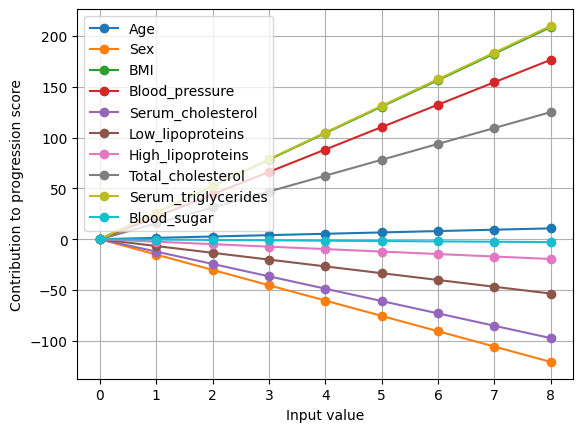

And the final constant offset is: 154.966


In [8]:
import matplotlib.pyplot as plt

# Grab a record of the predictive features
predictive_features = observations.drop(columns=target_feature).columns.to_numpy()

# Show learned coefficients (model parameters) graphically
plt.figure()
for index, c in enumerate(model.coef_):
  plt.plot(range(0,9), range(0,9)*c, marker='o', linestyle='-', label=predictive_features[index])
plt.xlabel('Input value')
plt.ylabel('Contribution to progression score')
plt.grid(True)
plt.legend()
plt.show()

# And the constant offset
print(f"And the final constant offset is: {model.intercept_:.3f}")

# Linear regression (gradient descent)

Now let's use Scikit-learn's `SGDRegressor` class to see how we can use _gradient descent_ to *search* for a linear regressor's parameters (instead of solving the *normal equation*).

This class uses stochastic gradient descent (SGD) to find the best set of model parameters by minimising a cost function (the MSE for the training data). It can be a very useful alternative where we have large amounts of training data, or where the normal equation calculation fails. **Gradient descent is also used in many other areas of machine learning and so it's an important technique to get used to.**

The main steps are as follows:

1.    start with a guess at the model parameters (a random location in parameter space);
2.    calculate the local gradient at that point in the cost surface;
3.    take a small jump in the opposite direction to improve our model parameters;
4.    Return to step 2.

Because the cost surface for LiR is *unimodal*, we can expect to reach the best possible set of model parameters as long as we descend the cost surface carefully (e.g., we don't try to jump too far and risk divergence).

Run the code and compare the result against the one you got with the `LinearRegression` class above.

*   What is the model's RMSE? ** 55.689 **

**Tip**: Notice this is another predictive model with a random element to its training phase (and therefore the ability to supply a random number seed for repeatable results). 'Stochastic' is just another word for random - referring to the random sampling of the training examples for local gradient estimation.

In [14]:
# Import the packages we need
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDRegressor

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/diabetes_progression.csv')

# Set the name of the target feature
target_feature = 'Progress'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing values ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_values = observations_test[target_feature].to_numpy()

# Split into training examples and training values ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_values = observations_train[target_feature].to_numpy()

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Create a linear regression model object (gradient descent):
model = SGDRegressor(random_state=99, verbose = 1, n_iter_no_change=15)

# Fit the model to our training data
model.fit(train_examples, train_values)

# Use the model to generate predictions for our testing examples
predictions = model.predict(test_examples)

# Calculate the model's mean square error (MSE) - the average square of the error between its predictions and the testing values
mse = np.sum( (predictions - test_values)**2 ) / len(test_values)
print(f"MSE: {mse:.3f}")
print(f"Root MSE: {np.sqrt(mse):.3f}")

-- Epoch 1
Norm: 32.72, NNZs: 10, Bias: 91.561276, T: 266, Avg. loss: 6951.631084
Total training time: 0.00 seconds.
-- Epoch 2
Norm: 38.29, NNZs: 10, Bias: 120.120433, T: 532, Avg. loss: 2762.821627
Total training time: 0.00 seconds.
-- Epoch 3
Norm: 41.24, NNZs: 10, Bias: 134.725444, T: 798, Avg. loss: 1898.573275
Total training time: 0.00 seconds.
-- Epoch 4
Norm: 42.89, NNZs: 10, Bias: 142.276949, T: 1064, Avg. loss: 1638.604161
Total training time: 0.00 seconds.
-- Epoch 5
Norm: 44.58, NNZs: 10, Bias: 147.091869, T: 1330, Avg. loss: 1549.033062
Total training time: 0.00 seconds.
-- Epoch 6
Norm: 45.32, NNZs: 10, Bias: 149.817787, T: 1596, Avg. loss: 1510.328022
Total training time: 0.00 seconds.
-- Epoch 7
Norm: 46.17, NNZs: 10, Bias: 151.668194, T: 1862, Avg. loss: 1494.460427
Total training time: 0.00 seconds.
-- Epoch 8
Norm: 46.99, NNZs: 10, Bias: 152.675769, T: 2128, Avg. loss: 1485.198603
Total training time: 0.00 seconds.
-- Epoch 9
Norm: 46.93, NNZs: 10, Bias: 153.497407, 

*    **Set the constructor's `verbose` option to be `1` and run the code again.**

You should see some debug that gives you some sense of what’s happening during gradient descent. Note in particular the 'Avg. loss' value (essentially the height of the cost surface) and how it gradually reduces over time.

*   What is the 'Avg. loss' value at the final epoch? ** 1475.265942 **

(For interest: it's actually the cost function score for the training data - which is just the MSE - divided by two, and averaged over the last epoch.)

## 1D model parameter visualisation

By copy/pasting from the earlier code listing, produce a visualisation of the contributions to the output made by each predictive feature in the range 0-8:

*    **Compare your plot with the earlier one - you should be able to spot small differences in the recovered model parameters**

**Tip**: While `LinearRegression` produces `.intercept_` as a float, `SGDRegressor` produces a NumPy array, so for the very last line of the previous code listing to work, you'll need to change `model.intercept_` into `model.intercept_[0]`.

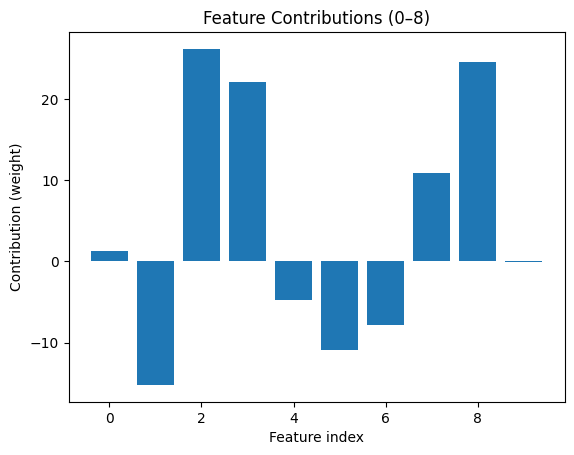

In [13]:
# Add your code on the lines below

import matplotlib.pyplot as plt

# Get the learned coefficients (weights)
coefficients = model.coef_

# Feature indices (0 to 8)
feature_indices = np.arange(len(coefficients))

# Plot
plt.figure()

plt.bar(feature_indices, coefficients)

plt.xlabel("Feature index")
plt.ylabel("Contribution (weight)")
plt.title("Feature Contributions (0–8)")

plt.show()



## Useful hyperparameters

It's not always the case that `SGDRegressor` (or any approach based on SGD) will recover good model parameters with its default hyperparameters.

The most useful hyperparameters for influencing the outcome are those that give you control over how big the jumps across the cost surface are allowed to be, and how long the gradient descent process is allowed to go on for. The model parameters you recover can be very sensitive to both:

*   `eta0` - this lets you control the 'learning rate' (you must also set `learning_rate='constant'` if you want to change it) or the size of the jump that is made across the cost surface based on each local gradient estimate - jumping further can get you to a solution quicker, but it can also cause you to jump too far and end up diverging from the solution
*   `max_iter` - this lets you control the maximum number of epochs that are allowed; this isn't quite the same as the maximum number of SGD gradient descent steps but you can think of it in roughly those terms (more precisely: one epoch is said to have passed once SGD has drawn as many samples as you have examples in your training data)
*    `tol` and `n_iter_no_change` - these parameters (either individually, or both together) let you terminate the gradient descent early if the cost scores are not improving; training will stop if the cost does not decrease by at least `tol` for `n_iter_no_change` consecutive epochs.


## You try one

In the code listing above, gradient descent terminates early because the cost scores eventually stop improving in large enough jumps. Try forcing it to run for a bit longer by increasing the `n_iter_no_change` value to 15 (it is 5 by default).

*    How many epochs are completed now? ** 62 **

**Tip**: You won't see big changes in terms of the performance on the testing data (SGD is already converging on the global minimum), but you should get a feel for controlling the number of training epochs that are taking place.

**Tip**: You can also cause the descent to continue for longer by decreasing `tol` and/or decreasing `eta0` (the learning rate).

# The sepal_regression.csv data

Let's introduce another group of data for regression: sepal_regression.csv. The challenge here is to predict 'petal_length' (in cm) from just two predictive features: 'sepal_width' and 'sepal_length' (both in cm).

We keep a copy of the sepal_regression data on an MMU web server for easy access and use in these labs: [sepal_length.csv](https://helward.mmu.ac.uk/STAFF/J.Darby/ML/sepal_length.csv)

Click the link to download the .csv file to your local machine, and open it up in Excel to have a quick look.

Here's a quick summary:
*    Number of observations = 150
*    Target feature = 'petal_length'
*    Number of predictive features = 2
*    Notes: not very interesting but good for feature space visualisation

## Feature space visualisation

For a dataset with only two predictive features, like sepal_regression.csv, we can visualise the feature space. We have a couple of different options for doing this with regression problems.

First, we use colour to represent the magnitude of the model's predictions in a 2D plot. Our approach is almost identical to the way we visualised feature spaces for classification problems previously, but now we must use the colour of the points in the space to represent *continuous* numerical target values:

**Tip**: The 'colourbar' on the right of the axes helps you to interpret the way colours are used to represent distances (in cm); it's fairly intuitive once you're used to it - essentially, brighter colours means larger distances.

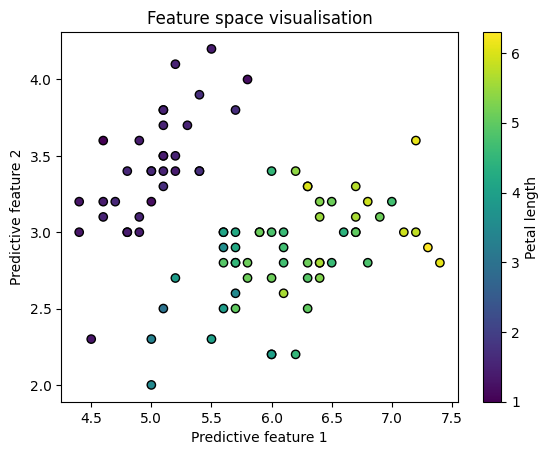

In [15]:
# Import the packages we use
import pandas as pd
import matplotlib.pyplot as plt

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/sepal_regression.csv')

# Set the name of the target feature
target_feature = 'petal_length'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing values ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_values = observations_test[target_feature].to_numpy()

# Split into training examples and training values ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_values = observations_train[target_feature].to_numpy()

# Visualise training data in feature space
plt.figure()

# Plot the training data (2D)
plt.scatter(train_examples[:, 0], train_examples[:, 1], c=train_values, edgecolors='black', cmap='viridis')

# Add a colorbar to help us interpret the colours
plt.colorbar(label='Petal length')

plt.xlabel('Predictive feature 1')
plt.ylabel('Predictive feature 2')
plt.title('Feature space visualisation')
plt.show()

Second, we can use an extra axis to represent the target feature values and move our visualisation into a 3D space. See the example below. We've left the colour coding on the scattered points to help with comparing between the two different visualisation options (but there's no requirement to use colour in this approach).

**Tip**: Doing this kind of plot with Matplotlib is possible and works well, but what doesn't work so well is _interacting_ with the plot in Colab afterwards (e.g., dragging it to spin it round). So we use the [plotly](https://plotly.com/python/) package instead, which is much more Colab-friendly. (Matplotlib is fine if you're working with Jupyter notebooks on your local machine.)

**Tip**: we set `aspectmode=cube` so that all the axes are the same length (with different scales) - this makes the plot fit more nicely into the notebook, but does slightly skew the appearance of the distribution - try deleting this line if you're interested to see its true shape.

In [16]:
# Import the packages we need
import plotly.graph_objects as go

# plot the training data (3D)
fig = go.Figure(data=[
    go.Scatter3d(
        x=train_examples[:, 0],
        y=train_examples[:, 1],
        z=train_values,
        mode="markers",
        marker=dict(
            size=5,
            color=train_values,
            colorscale="Viridis",
            showscale=True,
            line=dict(
                color="black",
                width=1
            )
        )
    )
])

# add some axis labels
fig.update_layout(
    title="Feature space visualisation",
    scene=dict(
        xaxis_title='Predictive feature 1',
        yaxis_title='Predictive feature 2',
        zaxis_title='Petal length',
        aspectmode='cube'
    )
)

fig.show()

## Generalisation visualisation

If we can plot the feature space, then we can also visualise how a model's `fit()` method has generalised based on our training data. I.e., for every possible coordinate in the feature space, what value would the model predict? (As with classification problems, in practice, we typically only look at a region that spans the original training data.)

We can do this using either of the two approaches we used above (by colour coding in 2D, or by using an extra axis in 3D).

The code below produces this visualisation for a linear regression model trained on the sepal_regression.csv data. It first covers the feature space in a dense grid of testing examples. It then passes those testing examples to the model to generate predicted values. Finally, it plots the grid, colour-coded by the resulting predicted values. (It also superimposes the training data on top of the grid, for extra context.)

Our approach is almost identical to the way we visualised feature spaces for classification problems previously, but now, again, we must use the colour of the points in the space to represent continuous numerical target values:


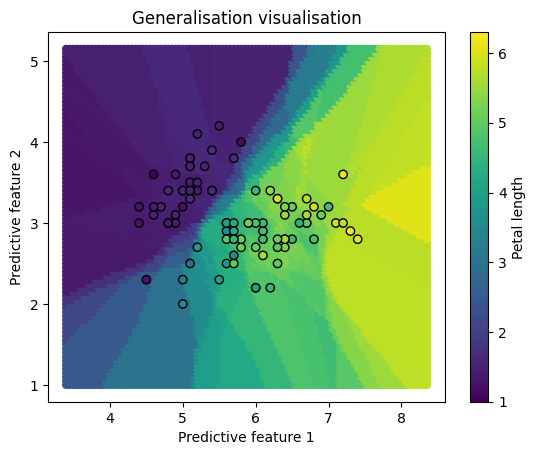

In [19]:
# Import the packages we use
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import SGDRegressor



from sklearn.neighbors import KNeighborsRegressor

# Try different k values (change this number)
model = KNeighborsRegressor(n_neighbors=5)


# Call the model's fitting/training algorithm, passing in our training examples and training values
model.fit(train_examples, train_values)

# Prepare our own grid of testing examples to use in visualization
x_min = train_examples[:, 0].min() - 1
x_max = train_examples[:, 0].max() + 1
y_min = train_examples[:, 1].min() - 1
y_max = train_examples[:, 1].max() + 1
# adjust this to get more/less definition in the grid (takes more/less time, may need smaller plot points below)
jump = 0.05
# Get help from numpy's meshgrid() function to be fast
grid_x, grid_y = np.meshgrid(np.arange(x_min, x_max, jump), np.arange(y_min, y_max, jump))
# Turn the results back into a deep table with only 2 columns
grid_examples = np.c_[grid_x.ravel(), grid_y.ravel()]

# Make predictions for each of the examples in the grid
grid_predictions = model.predict(grid_examples)

# Visualise the final generalisation
plt.figure()

# What are the biggest/smallest outputs we're dealing with - to help us get colour scaling correct
vmin = min(grid_predictions.min(), train_values.min())
vmax = max(grid_predictions.max(), train_values.max())

# Plot the generalisation
plt.scatter(grid_examples[:, 0], grid_examples[:, 1], c=grid_predictions, edgecolors='none', cmap='viridis', vmin=vmin, vmax=vmax)
# Plot the training data for context
plt.scatter(train_examples[:, 0], train_examples[:, 1], c=train_values, edgecolors='black', cmap='viridis', vmin=vmin, vmax=vmax)

# Add a colorbar to help us interpret the colours
plt.colorbar(label='Petal length')

plt.xlabel('Predictive feature 1')
plt.ylabel('Predictive feature 2')
plt.title('Generalisation visualisation')
plt.show()

Alternatively, we can do the same thing in our 3D feature space visualisation. This time, every prediction made by the model is at a different _height_. Notice that the result of adding together two independent linear relationships (one per predictive feature) at every point in the space is a flat plane. As before, we've left the colour coding on the plane to help with comparing between the two different visualisation options (but there's no requirement to use colour in this approach).

*    **Rotate around the space and have a good look at the model's generalisation - does it do a good job of explaining the training data? Yes it does **

**Tip**: the change to our previous Plotly code is quite small - notice we've just added an extra `go.Surface()` call, just like the ones we used in our Naive Bayes work (note that we have to reshape the `grid_predictions` to have the dimensions expected by Plotly).

**Tip**: as before, we're using `apectmode='cube'` - you can remove this line if you want to see the exact data distribution (see also the previous tip).

In [20]:
# Import the packages we need
import plotly.graph_objects as go

# plot the model generalisation (3D) and the training data
fig = go.Figure(data=[
    go.Surface(x=grid_x, y=grid_y, z=grid_predictions.reshape(grid_x.shape), colorscale="Viridis", cmin=vmin, cmax=vmax),
    go.Scatter3d(
        x=train_examples[:, 0],
        y=train_examples[:, 1],
        z=train_values,
        mode="markers",
        marker=dict(
            size=5,
            color=train_values,
            colorscale="Viridis",
            cmin=vmin,
            cmax=vmax,
            showscale=True,
            line=dict(
                color="black",
                width=1
            )
        )
    )
])

# add some axis labels
fig.update_layout(
    title="Generalisation visualisation",
    scene=dict(
        xaxis_title='Predictive feature 1',
        yaxis_title='Predictive feature 2',
        zaxis_title='Petal length',
        aspectmode='cube'
    )
)

fig.show()

*    **Replace the linear regression model in the code above with a k-NN regressor and have a look at the generalisations it produces - try a few different k-values**
*    Just from looking at the generalisation visualisation for the k-NN model and/or from your existing knowledge: is there a linear relationship between the inputs (the predictive feature values) and the k-NN regressor's output? ** Yes, the datapoints seem to be following a relativly straight line - linear movement**

# Regression model comparison

Conduct a full investigation into performance on the diabetes_progression.csv data using a `DecisionTreeRegressor`.

You should consider the following points as part of your investigation:

*    What hyperparameters settings will you investigate?
*    Can you improve your basic recipe to make use of validation data?
*    While still *only* using `DecisionTreeRegressor` models, can you produce an ensemble regression model that improves performance?
*    At the end of your investigation, how can you produce a robust estimate of expected future performance for the winning model configuration? (You'll need to plan for this right at the start of your investigation)

**Tip**: Remember that the diabetes_progression.csv data is already clean.

**Tip**: Stratified sampling isn't relevant for regression problems, so if you want to use cross-validation you can just use the `KFold` class (rather than the `StratifiedKFold` class). (See also the previous lab notebook.)

**Tip**: `cross_val_score()` will only return the negative of the MSE score (using the `neg_mean_squared_error` option). This is just because of a convention on trying to *maximise* performance scores in Scikit-learn. (Some other functions can call on this function in order to try and recover the best model performance automatically.)

**Tip**: the `DecisionTreeRegressor` isn't sensitive to predictive feature value ranges, but strong encouragement to use pipelines and z-score standardisation anyway, just be sure you know how to use them correctly when you need to.

In [21]:
# Add your code on the lines below:

# IMPORTS
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import BaggingRegressor

# LOAD DATA
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/diabetes_progression.csv')

target_feature = 'Progress'

X = observations.drop(columns=target_feature)
y = observations[target_feature]

# TRAIN / TEST SPLIT (for final evaluation)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=99
)

# PIPELINE (scaling + tree)
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('tree', DecisionTreeRegressor(random_state=99))
])

# HYPERPARAMETER GRID
param_grid = {
    'tree__max_depth': [2, 3, 5, 10, None],
    'tree__min_samples_split': [2, 5, 10],
    'tree__min_samples_leaf': [1, 2, 4]
}

# CROSS-VALIDATION
cv = KFold(n_splits=5, shuffle=True, random_state=99)

# GRID SEARCH
grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring='neg_mean_squared_error'
)

# FIT GRID SEARCH
grid.fit(X_train, y_train)

# BEST RESULTS
print("Best parameters:", grid.best_params_)
print("Best CV MSE:", -grid.best_score_)
print("Best CV RMSE:", np.sqrt(-grid.best_score_))

# ----------------------------
# ENSEMBLE (BAGGING)
# ----------------------------

best_tree = DecisionTreeRegressor(
    max_depth=grid.best_params_['tree__max_depth'],
    min_samples_split=grid.best_params_['tree__min_samples_split'],
    min_samples_leaf=grid.best_params_['tree__min_samples_leaf'],
    random_state=99
)

ensemble_model = BaggingRegressor(
    estimator=best_tree,
    n_estimators=10,
    random_state=99
)

# CROSS-VALIDATION FOR ENSEMBLE
ensemble_scores = cross_val_score(
    ensemble_model,
    X_train,
    y_train,
    cv=cv,
    scoring='neg_mean_squared_error'
)

print("Ensemble CV RMSE:", np.sqrt(-ensemble_scores.mean()))

# ----------------------------
# FINAL TEST EVALUATION
# ----------------------------

ensemble_model.fit(X_train, y_train)

preds = ensemble_model.predict(X_test)

mse = np.mean((preds - y_test)**2)
rmse = np.sqrt(mse)

print("Final TEST RMSE:", rmse)



Best parameters: {'tree__max_depth': 3, 'tree__min_samples_leaf': 1, 'tree__min_samples_split': 2}
Best CV MSE: 3919.0157131719425
Best CV RMSE: 62.60204240415757
Ensemble CV RMSE: 59.48618793593437
Final TEST RMSE: 56.481489599763634


# Extension tasks (optional)

(Extension tasks are optional. They don't map to the assessment on this module and there is no harm in skipping them. However, for people who are interested in the subject/planning to do further study, the extension tasks can help you deepen your machine learning knowledge and meet the module learning objectives more fully.)

## Linear regression (normal equation)

Let's train a linear regressor to have a play around with:

In [ ]:
# Import the packages we need
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

# Load all the observations from file
observations = pd.read_csv('https://helward.mmu.ac.uk/STAFF/J.Darby/ML/diabetes_progression.csv')

# Set the name of the target feature
target_feature = 'Progress'

# Shuffle all the observations
observations_shuffled = observations.sample(frac=1, random_state=99)

# Set the fraction of observations we will use for testing
testing_fraction = 0.4
split_index = int(observations_shuffled.shape[0] * testing_fraction)

# Split into testing observations and training observations ("horizontal split")
observations_test = observations_shuffled.iloc[:split_index]
observations_train = observations_shuffled.iloc[split_index:]

# Split into testing examples and testing values ("vertical split")
test_examples = observations_test.drop(columns=target_feature).to_numpy()
test_values = observations_test[target_feature].to_numpy()

# Split into training examples and training values ("vertical split")
train_examples = observations_train.drop(columns=target_feature).to_numpy()
train_values = observations_train[target_feature].to_numpy()

# Create a new StandardScaler object, ready to do z-score standardisation
scaler = StandardScaler()
# Compute means and standard deviations for each feature in the training data
scaler.fit(train_examples)
# Divide individual feature values in the training data by their respective means and standard deviations:
train_examples = scaler.transform(train_examples)
# Apply the same transformation to the testing examples
test_examples = scaler.transform(test_examples)

# Create a linear regression model object (normal equation):
model = LinearRegression()

# Fit the model to our training data
model.fit(train_examples, train_values)

LinearRegression()

### Generating predictions

Generating predictions with a linear regressor involves lots of multiplications and additions (multiply feature values by learned coefficients, and add up). The process can be simplified by using a package that supports [dot products](https://www.mathsisfun.com/algebra/vectors-dot-product.html) (e.g., NumPy), which are themselves just a series of multiplications and additions. The process can also be scaled up for multiple predictions by using a package that supports [matrix multiplications](https://www.mathsisfun.com/algebra/matrix-multiplying.html) (e.g., NumPy again!), which are themselves just a series of dot products.

We can write down an equation for the _single_ matrix multiplication needed to generate predictions for _all_ our testing examples, as follows:

$\bar{\mathbf{y}}^\text{c}=\dot{\mathbf{X}}\mathbf{a}^\text{c}$

Where:
*    $\bar{\mathbf{y}}^\text{c}$ is a column vector containing the new predictions
*    $\dot{\mathbf{X}}$ is a matrix containing all our testing examples (one per row)
*    $\mathbf{a}^\text{c}$ is a column vector containing our model parameters

Getting the shape of your matrices correct is critical for matrix multiplication to work. The number of columns in the first matrix must equal the number of rows in the second matrix. It's easy to make a mistake, but it's also usually pretty easy to fix your mistakes by printing out the shape of your matrices and checking them against the rule. Sometimes you might need to [transpose](https://www.mathsisfun.com/definitions/transpose-matrix-.html) one. Or it's very common to forget about the constant offset in linear regression, which requires adding an extra column of ones to your examples, and adding the constant value onto your collection of learned coefficients.

The following code uses the parameters recovered by the model to make some predictions manually, with a single matrix multiplication. Have a read over it and we'll review the important details below:

In [ ]:
# Use the trained model to generate predictions for our testing examples manually, with a matrix multiply

# Add a column of ones to the matrix of testing examples to account for the intercept
test_examples_with_intercept = np.c_[test_examples, np.ones((test_examples.shape[0], 1))]
# Get the model's parameters (coefficients and intercept) into a matrix with a single column ('column vector')
params = np.atleast_2d(np.append(model.coef_, model.intercept_)).T
# Calculate the predictions using a single matrix multiply
predictions = test_examples_with_intercept @ params

# Calculate the model's mean square error (MSE) - the average square of the error between its predictions and the testing values
mse = np.sum( (predictions - test_values)**2 ) / len(test_values)
print(f"MSE: {mse:.3f}")
print(f"Root MSE: {np.sqrt(mse):.3f}")


# Add your code on the lines below (see tasks below)





MSE: 1667835.332
Root MSE: 1291.447


Notes:
*   The NumPy .c_ object allows for column-wise concatenation of 2D NumPy arrays
*   The `.coef_` and `.intercept_` attributes of the model are already stored as 1D NumPy arrays (remember: these are not the same as 2D arrays with a single column/row)
*   The `atleast_2d()` function makes 1D arrays into matrices with a single row, by default (sometimes called 'row vectors')
*   All NumPy arrays have a `.T` attribute that lets you access a transposed version of the underlying array, and we use this attribute to switch from a matrix with a single row to one with a single column (or from a 'row vector' to a 'column vector')

Tasks:
1. What is the operator symbol for a matrix multiplication (it's actually a shorthand for NumPy's `matmul()` function)  **Type your answer here**
2. Add some debug to the code to confirm that the two matrices being multiplied have a compatible shape; i.e., what is the number of columns in the first matrix and the number of rows in the second matrix? **Type your answer here**
3. If you switched round the order in which the two matrices are being multiplied, then would it matter? **Type your answer here**

### Finding model parameters

NumPy is generally really useful (and fast) for performing matrix operations. Consider the *normal equation*, which can be used to find the model parameters from the matrix containing our training examples ($\mathbf{X}$) and a column vector of our training values ($\mathbf{y}^\text{c}$):

$\mathbf{a}^\text{r}=(\mathbf{X}^{\top}\mathbf{X})^{-1}\mathbf{X}^{\top}\mathbf{y}^\text{c}$

It contains a series of transposes and matrix multiplications and would be really hard work to do either with a pen and paper, or with a series of for-loops. It's a single line of code in NumPy, however... By first looking up any new NumPy functions you might need (e.g., for the matrix inversion), see if you can type it up and compare your result against the `params` variable from above by printing them both out:

**Tip**: $\mathbf{X}$ and $\mathbf{y}^\text{c}$ have been set up for you as `train_examples_with_intercept` and `train_values_column`, respectively.

In [ ]:
train_examples_with_intercept = np.c_[train_examples, np.ones((train_examples.shape[0], 1))]
train_values_column = train_values.T

# Add your code on the lines below:





The important overall conclusions are:
1. Matrix multiplications are a really useful tool (not only in the context of linear regression, but in machine learning more widely)
2. Don't be put off trying matrix operations even if you don't feel fully confident in what's happening - packages like NumPy take the pain away :)

### You try!

**Would you like to re-implement a `MyLinearRegression` class for linear regression (normal equation)? We have worked through the steps necessary for implementing the normal equation during model fitting, above. We have also looked at how to generate predictions with NumPy matrix multiplications. You would need to bring together these steps in a single class.**



## Linear regression (gradient descent)

### Estimating local gradient

Below is the equation for computing the local gradient (as a row vector, $\mathbf{v}^\text{r}$) at any point in the cost surface based on a matrix containing our training examples ($\mathbf{X}$), the corresponding predicted values generated by our model ($\mathbf{X}\mathbf{a}^\text{c}$), and a column vector of our true training values ($\mathbf{y}^\text{c}$):

$\mathbf{v}^\text{r}=\frac{1}{N}\mathbf{X}^{\top}(\mathbf{X}\mathbf{a}^\text{c} - \mathbf{y}^\text{c})$

Where $N$ is the number of training examples/values we have.

Again, by not worrying too much about the details of the matrix operations, see if you can use NumPy to calculate the local gradient vector based on the `SGDRegressor`'s initialisation of the model parameters - all zeros:

**Tip**: $\mathbf{X}$ and $\mathbf{y}^\text{c}$ have been set up for you as `train_examples_with_intercept` and `train_values_column`, respectively.

**Tip**: you should get the following result, which shows the direction in which we should jump (opposite way, distance controlled by the learning rate) in order to improve the current set of model parameters.

```
[[ -15.12070473]
 [  -2.63524564]
 [ -47.46812204]
 [ -37.04202997]
 [ -18.09415426]
 [ -14.80231918]
 [  29.86162282]
 [ -33.65155645]
 [ -46.06571027]
 [ -29.6446552 ]
 [-154.96616541]]
```

In [ ]:
train_examples_with_intercept = np.c_[train_examples, np.ones((train_examples.shape[0], 1))]
train_values_column = np.atleast_2d(train_values).T
# the model initialises parameters to zero
initial_params_column = np.zeros((train_examples.shape[1]+1,1))

# Add your code on the lines below:





### You try!

**Would you like to re-implement a `MySGDRegressor` class for linear regression (gradient descent)? We have worked through the steps necessary for finding the local gradient, above. We have also looked at how to generate predictions with NumPy matrix multiplications in the earlier extension tasks. You would need to bring together these steps in a single class.**

Further guidance:

1. After calculating the local gradient the main job is to then use it to make a change in the model parameters, based on a learning rate. Hard code this learning rate nice and small to begin with, along with a relatively small maximum on the number of iterations, and print yourself out plenty of debug at each step (current model parameters, local gradient, current cost score, etc.). Can you manage to recover a reasonable set of model parameters? (Compare against Scikit-learn's results.)
2. Can you extend your approach to support stochastic gradient descent (SGD) by allowing the number of training examples that are considered in the calculation to be adjusted, and sampled at random, through a 'batch size' setting (see also our work with `np.random.choice()` in previous weeks). An epoch is then defined as the number of iterations needed until you have sampled the same number of examples as are in your original training set - move to printing debug once per epoch, and give the caller control over the maximum number of epochs. Can you give them control over some other useful options (e.g., the batch size or learning rate, or equivalents to the `tol` and `n_iter_no_change` options we met in the earlier parts of the notebook).

## Other regressors

There are a few options here, depending on your interests:

1. We've mentioned that quite a few classification models can be repurposed for regression without going into the fine detail. Would you like to spend time researching and understanding the necessary modification for one (or more) of them in depth? You might: talk to YFLLM, ask questions to the lab tutors, search on Google/YouTube, look at the books on the module reading list, etc.
2. Would you like to adjust one of the previous model re-implementations shared on Moodle to create a new regression class? This is a good test of how well you've understood the necessary adjustments. Either k-Nearest neighbours or decision tree classifiers are relatively easy to convert.
3. If you worked on any of the ensemble re-implementation challenges previously (voting, bagging, random forests, etc.), or even if you didn't, would you like to try making regression versions now?